# Sparse regression and function discovery

The goal of this notebook is to understand the basic idea behind sparse
identification before applying it to dynamical systems.

Suppose that we observe pairs of points

$$
(x_i,y_i), \qquad y_i=f(x_i),
$$

but we do not know the function $f$.

Instead of choosing a particular form for $f$, we construct a **library of
candidate functions**

$$
\Theta(x) =
\begin{bmatrix}
1 & x & x^2 & x^3 & \sin(x) & \cos(x)
\end{bmatrix}.
$$

We then assume that

$$
f(x) \approx \Theta(x)\xi,
$$

where $\xi$ is a vector of coefficients.

If only a few entries of $\xi$ are non-zero, the resulting model is both
simple and interpretable. Our goal is therefore to find a **sparse**
coefficient vector $\xi$ from the observed data.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

Here we will generate synthetic functions that will serve as a test for sindy:

In [3]:
def f1(x):
    return 3 * np.sin(x)

def f2(x):
    return 2 - 3*x + 0.5*x**2

def f3(x):
    return 1.5*np.sin(x) - 2*x + 0.7*x**3

Now we generate the observations:

In [4]:
x = np.linspace(-2, 2, 200)

y1 = f1(x)
y2 = f2(x)
y3 = f3(x)

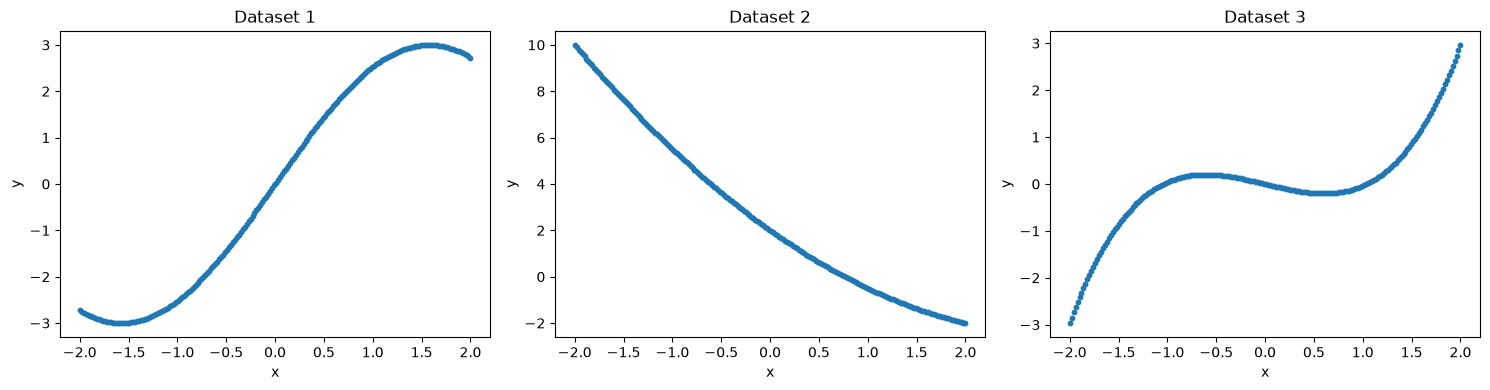

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(x, y1, s=10)
axes[0].set_title("Dataset 1")

axes[1].scatter(x, y2, s=10)
axes[1].set_title("Dataset 2")

axes[2].scatter(x, y3, s=10)
axes[2].set_title("Dataset 3")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

## The candidate-function library

We do not know which mathematical terms occur in $f(x)$.

We therefore construct a library containing several possibilities:

$$
1,\quad x,\quad x^2,\quad x^3,\quad x^4,\quad x^5,\quad
\sin(x),\quad \cos(x).
$$

For $N$ observations, these functions form the columns of a matrix

$$
\Theta =
\begin{bmatrix}
1 & x_1 & x_1^2 & \cdots & \sin(x_1) & \cos(x_1)\\
1 & x_2 & x_2^2 & \cdots & \sin(x_2) & \cos(x_2)\\
\vdots & \vdots & \vdots & & \vdots & \vdots\\
1 & x_N & x_N^2 & \cdots & \sin(x_N) & \cos(x_N)
\end{bmatrix}.
$$

Finding the unknown function is now equivalent to finding coefficients
$\xi$ such that

$$
y \approx \Theta\xi.
$$

In [6]:
def build_library(x):
    """
    Construct a library of candidate functions.

    Each column corresponds to one possible term in the model.
    """

    Theta = np.column_stack([
        np.ones_like(x),
        x,
        x**2,
        x**3,
        x**4,
        x**5,
        np.sin(x),
        np.cos(x)
    ])

    names = [
        "1",
        "x",
        "x^2",
        "x^3",
        "x^4",
        "x^5",
        "sin(x)",
        "cos(x)"
    ]

    return Theta, names


Theta, names = build_library(x)

print("Shape of the library:", Theta.shape)
print("Candidate functions:", names)

Shape of the library: (200, 8)
Candidate functions: ['1', 'x', 'x^2', 'x^3', 'x^4', 'x^5', 'sin(x)', 'cos(x)']


Can you explain what the next print statement means?

In [7]:
print(Theta[:5])

[[  1.          -2.           4.          -8.          16.
  -32.          -0.90929743  -0.41614684]
 [  1.          -1.9798995    3.92000202  -7.76121003  15.36641584
  -30.423959    -0.91747794  -0.39778667]
 [  1.          -1.95979899   3.8408121   -7.52721969  14.75183759
  -28.91063649  -0.92528777  -0.37926578]
 [  1.          -1.93969849   3.76243024  -7.29798027  14.15588132
  -27.45814166  -0.93272378  -0.36059167]
 [  1.          -1.91959799   3.68485644  -7.07344302  13.57816701
  -26.06462209  -0.93978295  -0.34177188]]


Abdelhamid answer: it shows the first 5 columns and the first 5 rows of Theta. That is, the first 5 evaluations of the first 5 candidate functions in the library.


## Step 1: ordinary least squares

We first ignore sparsity and solve

$$
\min_\xi \|y-\Theta\xi\|_2^2.
$$

The least-squares solution gives the combination of library functions
that best reproduces the observations.

In [8]:
def least_squares(Theta, y):
    xi, _, _, _ = np.linalg.lstsq(Theta, y, rcond=None)
    return xi


xi1 = least_squares(Theta, y1)
xi2 = least_squares(Theta, y2)
xi3 = least_squares(Theta, y3)

array([-2.72789228, -2.75243382, -2.77586332, -2.79817133, -2.81934884,
       -2.83938728, -2.85827856, -2.87601504, -2.89258957, -2.90799545,
       -2.92222645, -2.93527682, -2.94714129, -2.95781506, -2.96729383,
       -2.97557376, -2.98265152, -2.98852423, -2.99318952, -2.99664552,
       -2.99889083, -2.99992453, -2.99974622, -2.99835595, -2.9957543 ,
       -2.99194232, -2.98692154, -2.980694  , -2.9732622 , -2.96462916,
       -2.95479836, -2.94377378, -2.93155985, -2.91816153, -2.90358423,
       -2.88783383, -2.87091669, -2.85283966, -2.83361003, -2.81323558,
       -2.79172453, -2.76908558, -2.74532788, -2.72046101, -2.69449504,
       -2.66744044, -2.63930815, -2.61010954, -2.5798564 , -2.54856096,
       -2.51623585, -2.48289415, -2.44854931, -2.41321522, -2.37690615,
       -2.33963677, -2.30142214, -2.2622777 , -2.22221926, -2.181263  ,
       -2.13942548, -2.0967236 , -2.0531746 , -2.00879609, -1.96360599,
       -1.91762256, -1.87086438, -1.82335034, -1.77509964, -1.72

In [11]:
def print_model(xi, names, tol=1e-10):
    for coefficient, name in zip(xi, names):
        if abs(coefficient) > tol:
            print(f"{coefficient:+.6f}  {name}")


print("Function 1:")
print_model(xi1, names)

print("\nFunction 2:")
print_model(xi2, names)

print("\nFunction 3:")
print_model(xi3, names)

Function 1:
+3.000000  sin(x)

Function 2:
+2.000000  1
-3.000000  x
+0.500000  x^2

Function 3:
-2.000000  x
+0.700000  x^3
+1.500000  sin(x)


There is actually an interesting issue here: the sine example may expose collinearity/numerical conditioning, because on a finite interval a sufficiently flexible polynomial can approximate sine. For that reason merely solving least squares is not the whole story.

## Step 2: sparsity

Ordinary least squares only tries to minimize the reconstruction error.
It does not explicitly prefer simple models.

However, we expect that the true function contains only a few terms from
our candidate library.

For example, although our library contains eight possible functions,

$$
\Theta(x)=
[1,x,x^2,x^3,x^4,x^5,\sin(x),\cos(x)],
$$

the function

$$
f(x)=2-3x+\frac{1}{2}x^2
$$

requires only three of them.

We therefore want most entries of $\xi$ to be zero.

A simple algorithm used in SINDy is **Sequentially Thresholded Least
Squares (STLSQ)**:

1. Solve the least-squares problem.
2. Set coefficients smaller than a threshold $\lambda$ to zero.
3. Solve least squares again using only the remaining terms.
4. Repeat until the selected terms no longer change.

In [12]:
def stlsq(Theta, y, threshold=0.1, max_iter=10):
    """
    Sequentially Thresholded Least Squares.
    """

    # Initial least-squares solution
    xi = np.linalg.lstsq(Theta, y, rcond=None)[0]

    for _ in range(max_iter):

        # Identify small coefficients
        small = np.abs(xi) < threshold

        # Set them to zero
        xi[small] = 0.0

        # Which terms remain?
        active = ~small

        # Stop if everything has been removed
        if not np.any(active):
            break

        # Refit using only the active terms
        xi_active = np.linalg.lstsq(
            Theta[:, active],
            y,
            rcond=None
        )[0]

        # Put the coefficients back into the full vector
        xi[:] = 0.0
        xi[active] = xi_active

    return xi

In [ ]:
xi1_sparse = stlsq(Theta, y1, threshold=0.1)
xi2_sparse = stlsq(Theta, y2, threshold=0.1)
xi3_sparse = stlsq(Theta, y3, threshold=0.1)

print("Discovered function 1:")
print_model(xi1_sparse, names)

print("\nDiscovered function 2:")
print_model(xi2_sparse, names)

print("\nDiscovered function 3:")
print_model(xi3_sparse, names)

Discovered function 1:
+3.000000  sin(x)

Discovered function 2:
+2.000000  1
-3.000000  x
+0.500000  x^2

Discovered function 3:
-2.000000  x
+0.700000  x^3
+1.500000  sin(x)


We can now reconstruct the discovered functions:

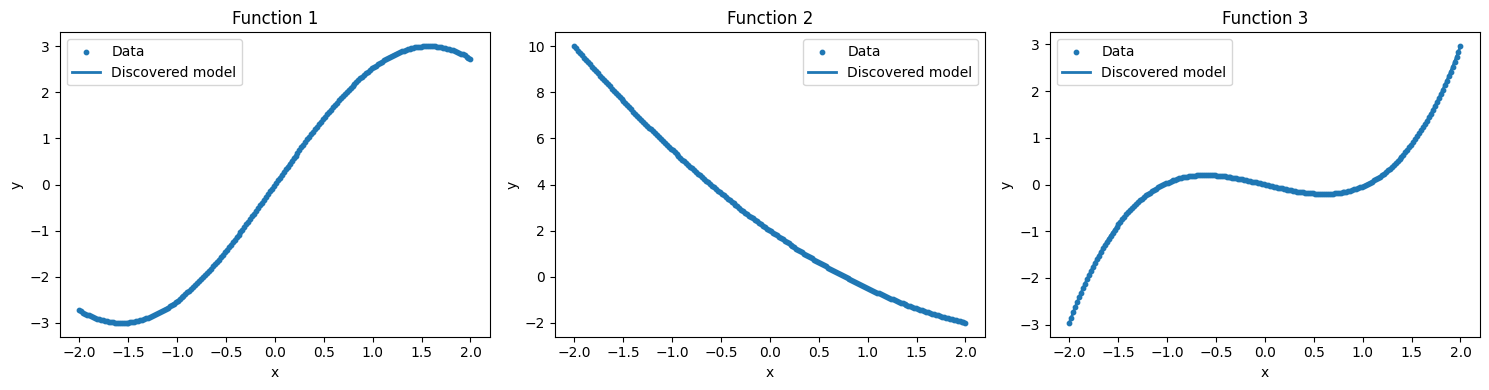

In [ ]:
y1_pred = Theta @ xi1_sparse
y2_pred = Theta @ xi2_sparse
y3_pred = Theta @ xi3_sparse

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datasets = [
    (y1, y1_pred, "Function 1"),
    (y2, y2_pred, "Function 2"),
    (y3, y3_pred, "Function 3")
]

for ax, (y, y_pred, title) in zip(axes, datasets):
    ax.scatter(x, y, s=10, label="Data")
    ax.plot(x, y_pred, linewidth=2, label="Discovered model")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

## From function discovery to dynamical systems

So far, we assumed that

$$
y=f(x)
$$

and tried to discover $f$ from observations.

For a dynamical system, the idea is almost identical. Suppose

$$
\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}).
$$

Instead of predicting $y$, we now try to predict the **time derivative**
of the state:

$$
\dot{X} \approx \Theta(X)\Xi.
$$

Here:

- $X$ contains observations of the state variables;
- $\dot{X}$ contains their time derivatives;
- $\Theta(X)$ contains candidate functions of the state variables;
- $\Xi$ contains the coefficients that define the discovered equations.

The central idea remains the same:

> **Find a small number of functions from a large candidate library that
> explain the observed data.**

For the Lorenz system, for example, a polynomial library might contain a different library. SINDy asks which of these terms are actually needed to explain $\dot{x}$, $\dot{y}$ and $\dot{z}$.

This is the problem we will consider in our project.